In [1]:
DATA_DIR = './Data'

In [2]:
import numpy as np


class Cutpoints:
    """Binarizes each continuous feature using class-transition cutpoints:
    a cutpoint is placed between two consecutive distinct values of a feature
    whenever the set of class labels present changes there."""

    def fit(self, X, y):
        self.cutpoints_ = []  # list of (feature_index, threshold)
        for j in range(X.shape[1]):
            col = X[:, j]
            order = np.argsort(col)
            sv, sy = col[order], y[order]
            prev = {sy[0]}
            for i in range(1, len(sv)):
                if sv[i] == sv[i - 1]:
                    prev.add(sy[i])
                    continue
                cur = {sy[i]}
                k = i
                while k + 1 < len(sv) and sv[k + 1] == sv[i]:
                    k += 1
                    cur.add(sy[k])
                if prev != cur or len(prev) > 1 or len(cur) > 1:
                    self.cutpoints_.append((j, (sv[i - 1] + sv[i]) / 2.0))
                prev = cur
        return self

    def transform(self, X):
        cols = [(X[:, j] <= t) for j, t in self.cutpoints_]
        return np.column_stack(cols) if cols else np.empty((X.shape[0], 0), dtype=bool)


class SimpleLADClassifier:
    """Sequential-covering rule learner over binarized (cutpoint) features.

    min_purity     : a rule stops growing once this fraction of what it covers is the target class
    min_coverage   : a rule must cover at least this many points
    max_conditions : maximum number of conditions per rule (readability)
    """

    def __init__(self, min_purity=0.9, min_coverage=15, max_conditions=4):
        self.min_purity = min_purity
        self.min_coverage = min_coverage
        self.max_conditions = max_conditions

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.binarizer_ = Cutpoints().fit(X, y)
        Xbin = self.binarizer_.transform(X)
        n_attrs = Xbin.shape[1]
        classes, counts = np.unique(y, return_counts=True)
        self.majority_class_ = classes[np.argmax(counts)]
        self.rules_ = []

        for cls in classes:
            is_pos = (y == cls)
            remaining_pos = is_pos.copy()
            for _ in range(50):  # hard cap on rules per class
                if remaining_pos.sum() < self.min_coverage:
                    break
                # search only over still-uncovered positives + all negatives
                active = remaining_pos | (~is_pos)
                conditions = []
                for _c in range(self.max_conditions):
                    best_gain = best_attr = best_dir = best_prec = None
                    for attr in range(n_attrs):
                        for keep_le in (True, False):
                            m = Xbin[:, attr] if keep_le else ~Xbin[:, attr]
                            cand = active & m
                            cov = cand.sum()
                            if cov < self.min_coverage:
                                continue
                            prec = (cand & is_pos).sum() / cov
                            gain = (prec, cov)
                            if best_gain is None or gain > best_gain:
                                best_gain, best_attr, best_dir, best_prec = gain, attr, keep_le, prec
                    if best_attr is None:
                        break
                    conditions.append((best_attr, best_dir))
                    active = active & (Xbin[:, best_attr] if best_dir else ~Xbin[:, best_attr])
                    if best_prec >= self.min_purity:
                        break
                cov_count = active.sum()
                if cov_count < self.min_coverage or not conditions or (active & remaining_pos).sum() == 0:
                    break
                self.rules_.append({
                    'class_': cls, 'conditions': conditions,
                    'precision': (active & is_pos).sum() / cov_count,
                    'coverage': int(cov_count),
                })
                remaining_pos = remaining_pos & ~active

        self.rules_.sort(key=lambda r: -r['precision'])  # most confident rule first
        return self

    def predict(self, X):
        Xbin = self.binarizer_.transform(np.asarray(X))
        preds = np.full(Xbin.shape[0], self.majority_class_)
        matched = np.zeros(Xbin.shape[0], dtype=bool)
        for rule in self.rules_:
            mask = np.ones(Xbin.shape[0], dtype=bool)
            for attr, keep_le in rule['conditions']:
                mask &= (Xbin[:, attr] if keep_le else ~Xbin[:, attr])
            preds[mask & ~matched] = rule['class_']
            matched |= mask
        return preds

    def rules_as_text(self, feature_names=None):
        lines = []
        for rule in self.rules_:
            parts = []
            for attr, keep_le in rule['conditions']:
                j, thr = self.binarizer_.cutpoints_[attr]
                name = feature_names[j] if feature_names is not None else f'x{j}'
                parts.append(f'{name} {"<=" if keep_le else ">"} {thr:.4f}')
            lines.append(f"IF {' AND '.join(parts)} THEN cluster={rule['class_']} "
                         f"(precision={rule['precision']:.2f}, coverage={rule['coverage']})")
        return '\n'.join(lines)


In [4]:
import pandas as pd, numpy as np, time
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

df = pd.read_csv(f'{DATA_DIR}/train_FD004_with_clusters.csv')
sensor_cols = [c for c in df.columns if c.startswith('s_')]

units = df['unit_number'].unique()
train_units, val_units = train_test_split(units, test_size=0.2, random_state=42)
train_df = df[df['unit_number'].isin(train_units)]
val_df = df[df['unit_number'].isin(val_units)].copy()
X_val, y_val = val_df[sensor_cols].values, val_df['cluster'].values
print(len(train_df), 'train rows,', len(val_df), 'val rows')

49294 train rows, 11955 val rows


In [5]:
PER_CLASS = 400
lad_train = pd.concat([g.sample(min(len(g), PER_CLASS), random_state=42) for _, g in train_df.groupby('cluster')])
X_train, y_train = lad_train[sensor_cols].values, lad_train['cluster'].values
print(X_train.shape)

(1200, 14)


In [6]:
rows = []
for p in [0.98, 0.95, 0.90, 0.85]:
    t0 = time.time()
    m = SimpleLADClassifier(min_purity=p, min_coverage=15, max_conditions=4).fit(X_train, y_train)
    f1 = f1_score(y_val, m.predict(X_val), average='macro')
    rows.append({'purity': p, 'macro_f1': f1, 'n_rules': len(m.rules_)})
    print(f'purity={p}: macro-F1={f1:.3f}, {len(m.rules_)} rules, {time.time()-t0:.1f}s')
purity_df = pd.DataFrame(rows)

purity=0.98: macro-F1=0.928, 39 rules, 15.1s
purity=0.95: macro-F1=0.928, 39 rules, 14.4s
purity=0.9: macro-F1=0.931, 40 rules, 13.7s
purity=0.85: macro-F1=0.931, 40 rules, 12.8s


In [7]:
best_purity = float(purity_df.loc[purity_df['macro_f1'].idxmax(), 'purity'])
lad_final = SimpleLADClassifier(min_purity=best_purity, min_coverage=15, max_conditions=4).fit(X_train, y_train)
print(f'min_purity={best_purity}, {len(lad_final.rules_)} rules\n')
print(lad_final.rules_as_text(feature_names=sensor_cols))

min_purity=0.85, 40 rules

IF s_15 > 1.0065 THEN cluster=0 (precision=1.00, coverage=126)
IF s_15 > 0.5424 AND s_2 > 0.1002 THEN cluster=0 (precision=1.00, coverage=54)
IF s_15 > 0.3399 AND s_4 > 0.3553 THEN cluster=0 (precision=1.00, coverage=33)
IF s_15 > 0.0339 AND s_11 > 0.4870 THEN cluster=0 (precision=1.00, coverage=15)
IF s_12 > 1.0520 THEN cluster=1 (precision=1.00, coverage=297)
IF s_15 <= -1.2863 THEN cluster=1 (precision=1.00, coverage=27)
IF s_11 <= -1.2999 THEN cluster=2 (precision=1.00, coverage=73)
IF s_4 <= -1.5226 THEN cluster=2 (precision=1.00, coverage=22)
IF s_17 <= -1.2995 AND s_8 <= 0.1439 THEN cluster=2 (precision=1.00, coverage=19)
IF s_11 <= -0.6755 AND s_2 <= -0.7132 THEN cluster=2 (precision=1.00, coverage=21)
IF s_11 <= -1.0402 THEN cluster=2 (precision=0.98, coverage=45)
IF s_2 <= -1.6021 THEN cluster=2 (precision=0.95, coverage=21)
IF s_11 <= -0.6938 AND s_4 <= -0.5680 THEN cluster=2 (precision=0.95, coverage=20)
IF s_15 > -0.0311 AND s_17 > 0.5953 THEN cl

              precision    recall  f1-score   support

   cluster_0       0.91      0.98      0.94      5952
   cluster_1       0.94      0.95      0.94      1620
   cluster_2       0.95      0.86      0.91      4383

    accuracy                           0.93     11955
   macro avg       0.94      0.93      0.93     11955
weighted avg       0.93      0.93      0.93     11955



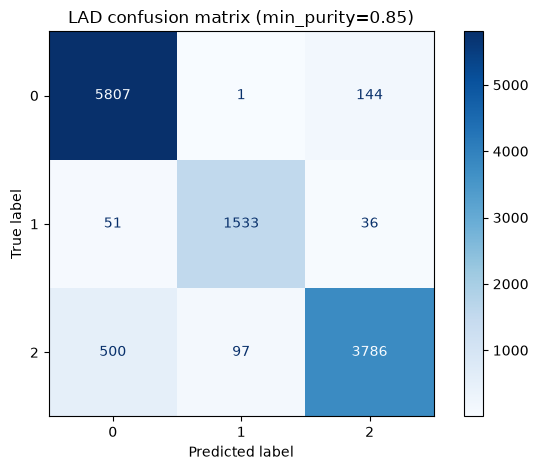

In [8]:
pred_val = lad_final.predict(X_val)
labels = sorted(df['cluster'].unique())
print(classification_report(y_val, pred_val, target_names=[f'cluster_{c}' for c in labels]))

ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val), display_labels=labels).plot(cmap='Blues')
plt.title(f'LAD confusion matrix (min_purity={best_purity})')
plt.tight_layout(); plt.savefig('lad_confusion_matrix.png', dpi=120); plt.show()

In [9]:
val_df['lad_prediction'] = pred_val
print(val_df.groupby('lad_prediction')['RUL'].describe()[['count', 'mean', '50%', 'min', 'max']].round(1))

                 count   mean    50%   min    max
lad_prediction                                   
0               6358.0   84.0   95.0   0.0  125.0
1               1631.0   59.0   49.0   0.0  125.0
2               3966.0  118.5  125.0  36.0  125.0


In [10]:
val_df.to_csv(f'{DATA_DIR}/val_FD004_with_lad_predictions.csv', index=False)
with open(f'{DATA_DIR}/lad_rules.txt', 'w') as f:
    f.write(lad_final.rules_as_text(feature_names=sensor_cols))
print('Saved predictions and rules.')

Saved predictions and rules.
